# Test: figure fonts

Same figure each time (PD Ghan decomposition, NET, LCC_PD − CTRL_PD, 2001–2009, current map style: bold mean, italic subtitle, 10 pt colourbar numbers). Only the font changes.
Text and math (mathtext, used for the bold mean, the italic *Under the maps*, units such as W m⁻²) are set to the same font, so mixed text stays consistent.

| Option | Font | Source | Look |
|---|---|---|---|
| A | STIXGeneral | system | previous default, Times-like serif |
| B | DejaVu Sans | system | matplotlib default sans |
| C | DejaVu Serif | system | wide serif |
| D | Cantarell | system | **chosen 2026-10-28 → `style.py`**; humanist sans, **no italic** (here subtitle upright; in `style.py` math italic = DejaVu Sans Oblique) |
| E | DejaVu Sans Condensed | system | narrow sans |
| F | Liberation Sans | downloaded | same widths as **Arial** |
| G | TeX Gyre Heros | downloaded | **Helvetica** clone |
| H | TeX Gyre Heros Cn | downloaded | condensed Helvetica clone (room for long titles) |
| I | Fira Sans | downloaded | humanist sans, has semibold |
| J | Lato | downloaded | rounded sans |
| K | Liberation Serif | downloaded | same widths as **Times New Roman** |

**Downloaded fonts** (2026-10-28, free licences: OFL / GPL+font exception) are in `~/.local/share/fonts/plot-tests/` (Fira Sans, Lato: github.com/google/fonts; Liberation 2.1.5: github.com/liberationfonts; TeX Gyre Heros 2.004: gust.org.pl). They are registered below with `font_manager.fontManager.addfont`, so this works without a font-cache rebuild.
To use one in the paper figures, `style.py` would need the same `addfont` call (or the files copied into the repo).
TeX Gyre fonts are `.otf` (CFF outlines). PNG output works, but **PDF/EPS export may fail or fall back** (matplotlib embeds only TrueType well) (c, not tested). The Liberation fonts are `.ttf` and safe.
**Dropped:** Computer Modern (`cmr10`, LaTeX look). The installed cmr10 is TeX-encoded and has no –, ±, ° or _ glyphs. IBM Plex Sans and Source Sans: only variable fonts on Google Fonts (matplotlib reads one instance only), not tried.
Missing weights fall back: `semibold` → bold except in Fira Sans.

Figures: `test_fonts_outputs/ghan_PD_NET_<option>.png`. Data: the 2001–2009 archive folder (`2001-2009-pre-co2-fix/`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from matplotlib import font_manager
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

# 2001-2009 processed files were archived on 2026-10-28 (CLAUDE.md, run-version rule step 2 (i))
fm.POSTPROCESSED_DIR = fm.POSTPROCESSED_DIR / "2001-2009-pre-co2-fix"
OUT = Path.cwd() / "test_fonts_outputs"
OUT.mkdir(exist_ok=True)

FONT_DIR = Path.home() / ".local/share/fonts/plot-tests"
for f in sorted(FONT_DIR.glob("*.[ot]tf")):
    font_manager.fontManager.addfont(str(f))

def custom(font):
    return {"font.family": font, "mathtext.fontset": "custom", "mathtext.rm": font,
            "mathtext.it": f"{font}:italic", "mathtext.bf": f"{font}:bold"}

FONTS = {
    "A_STIX": {"font.family": "STIXGeneral", "mathtext.fontset": "stix"},
    "B_DejaVuSans": {"font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans"},
    "C_DejaVuSerif": {"font.family": "DejaVu Serif", "mathtext.fontset": "dejavuserif"},
    "D_Cantarell": custom("Cantarell"),
    "E_DejaVuSansCondensed": custom("DejaVu Sans Condensed"),
    "F_LiberationSans": custom("Liberation Sans"),
    "G_TeXGyreHeros": custom("TeX Gyre Heros"),
    "H_TeXGyreHerosCn": custom("TeX Gyre Heros Cn"),
    "I_FiraSans": custom("Fira Sans"),
    "J_Lato": custom("Lato"),
    "K_LiberationSerif": custom("Liberation Serif"),
}

def font_figure(name):
    set_default_style()
    with plt.rc_context(FONTS[name]):
        fig, axes = fm.make_ghan_figure("PD", "total", "NET", start_year=2001, end_year=2009, save=False)
        fig.savefig(OUT / f"ghan_PD_NET_{name}.png", dpi=200, bbox_inches="tight")
        plt.show(); plt.close(fig)

## A: STIX (current)

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.


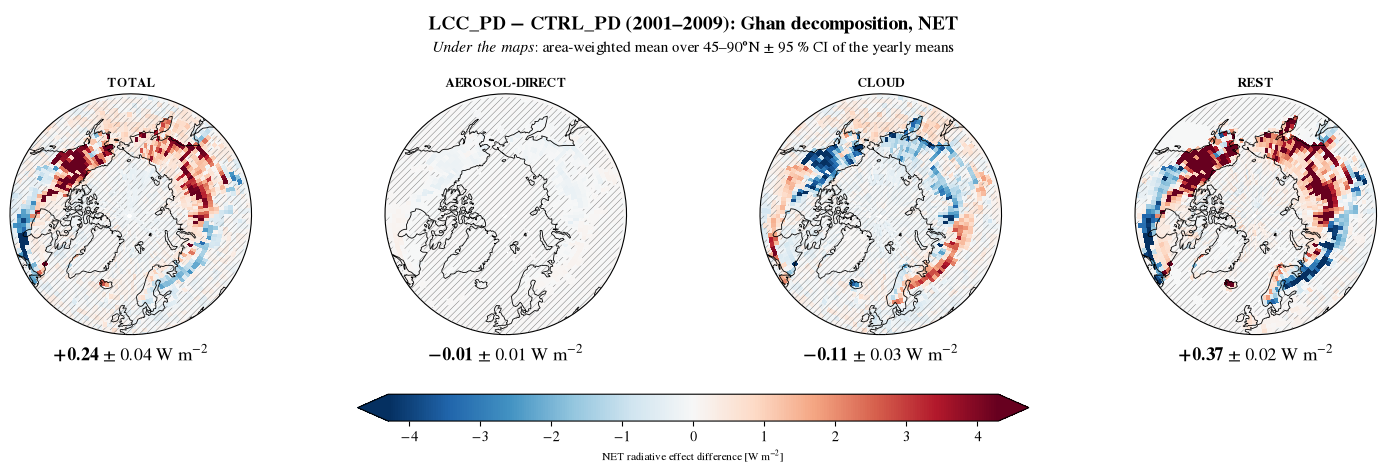

In [2]:
font_figure("A_STIX")

## B: DejaVu Sans

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.


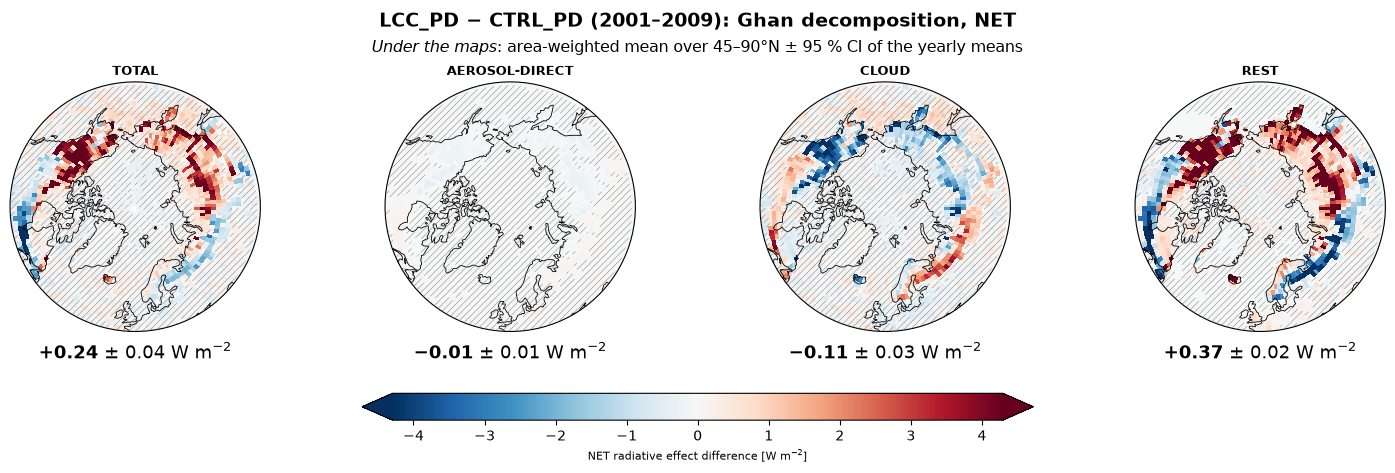

In [3]:
font_figure("B_DejaVuSans")

## C: DejaVu Serif

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.


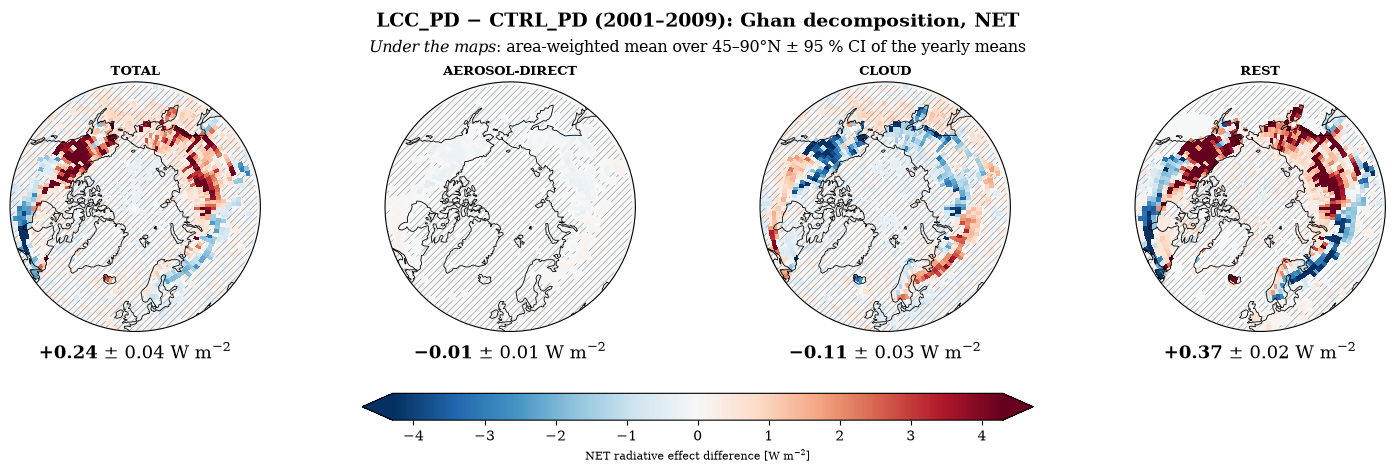

In [4]:
font_figure("C_DejaVuSerif")

## D: Cantarell

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


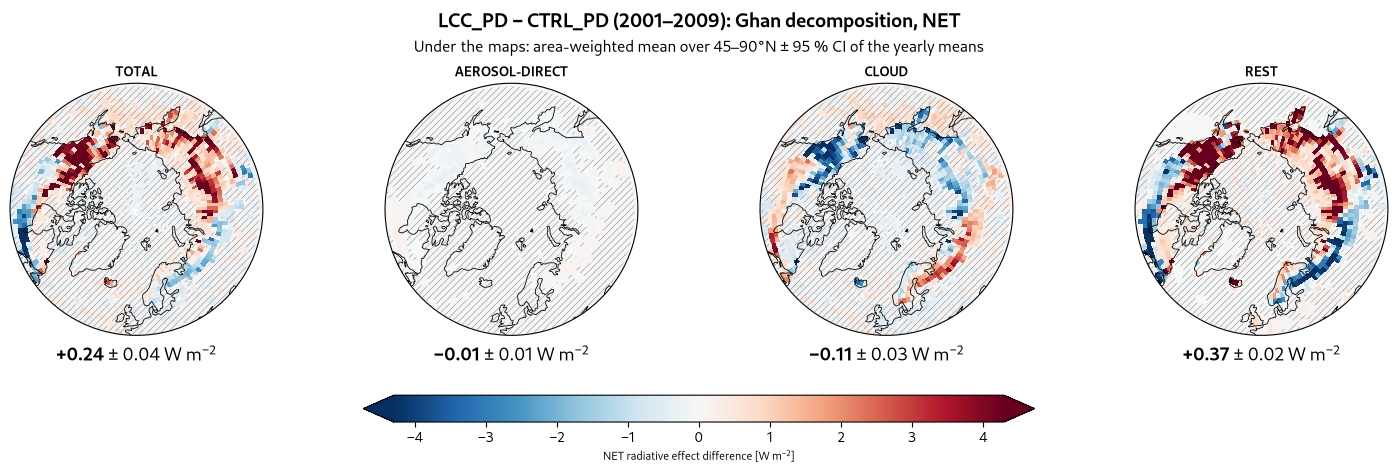

In [5]:
font_figure("D_Cantarell")

## E: DejaVu Sans Condensed

findfont: Failed to find font weight normal, now using 380.


Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.
findfont: Failed to find font weight normal, now using 380.


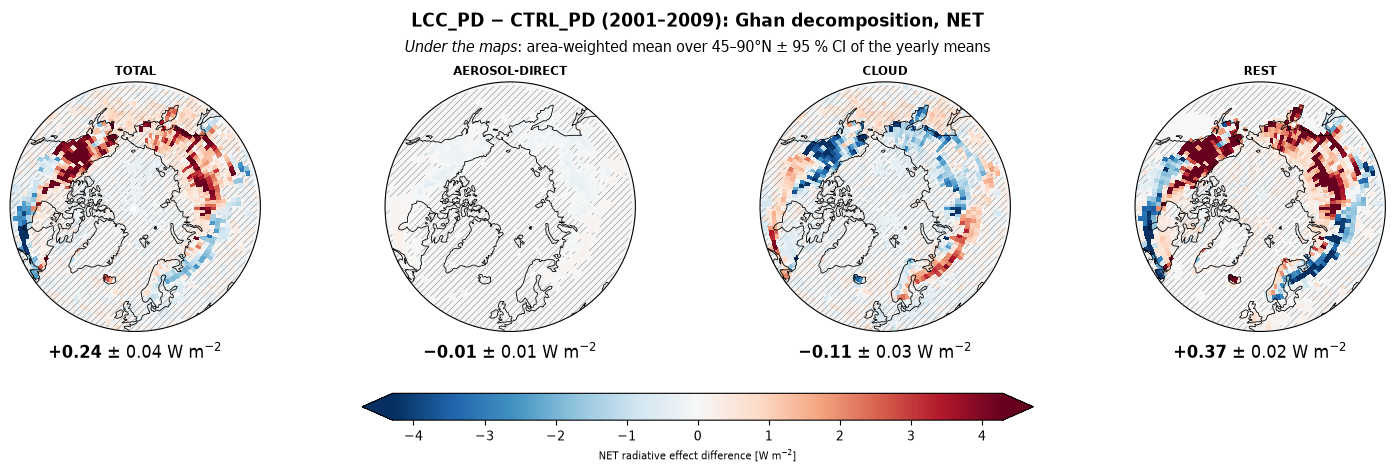

In [6]:
font_figure("E_DejaVuSansCondensed")

## F: Liberation Sans (Arial metrics)

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


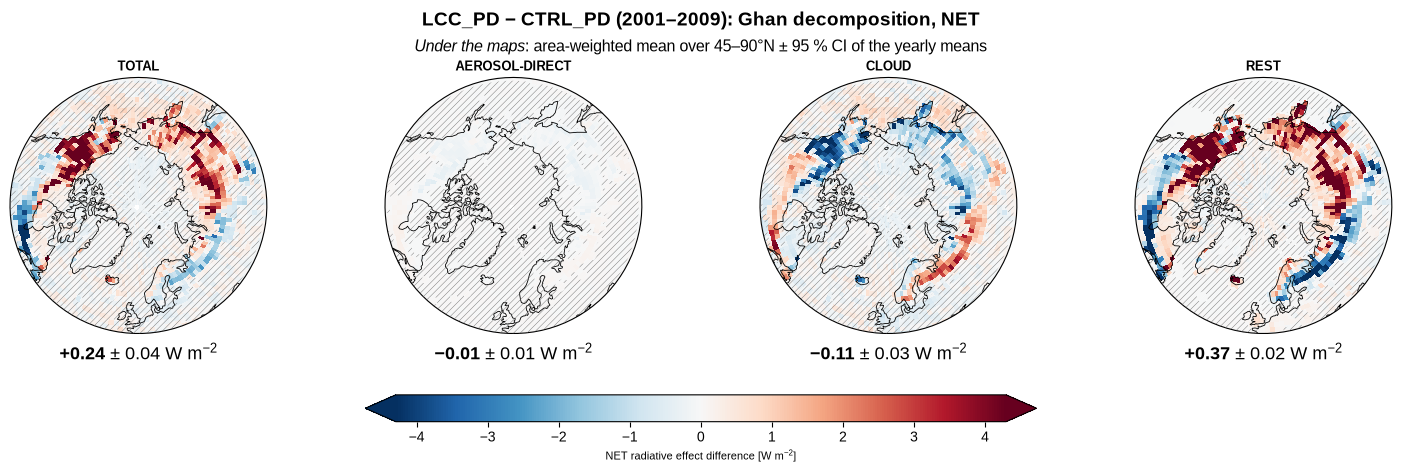

In [7]:
font_figure("F_LiberationSans")

## G: TeX Gyre Heros (Helvetica clone)

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


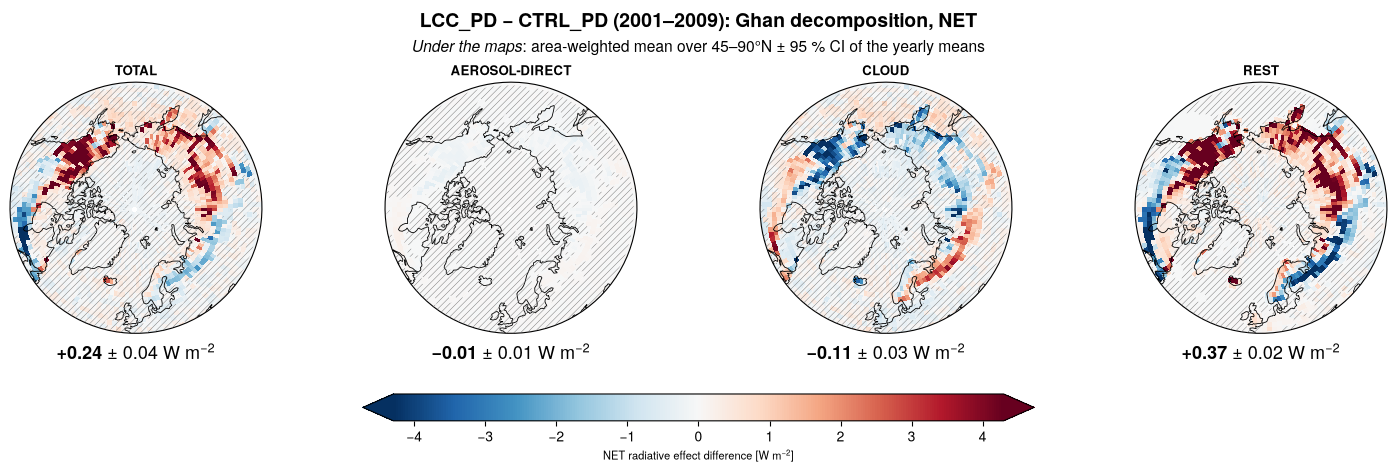

In [8]:
font_figure("G_TeXGyreHeros")

## H: TeX Gyre Heros Condensed

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


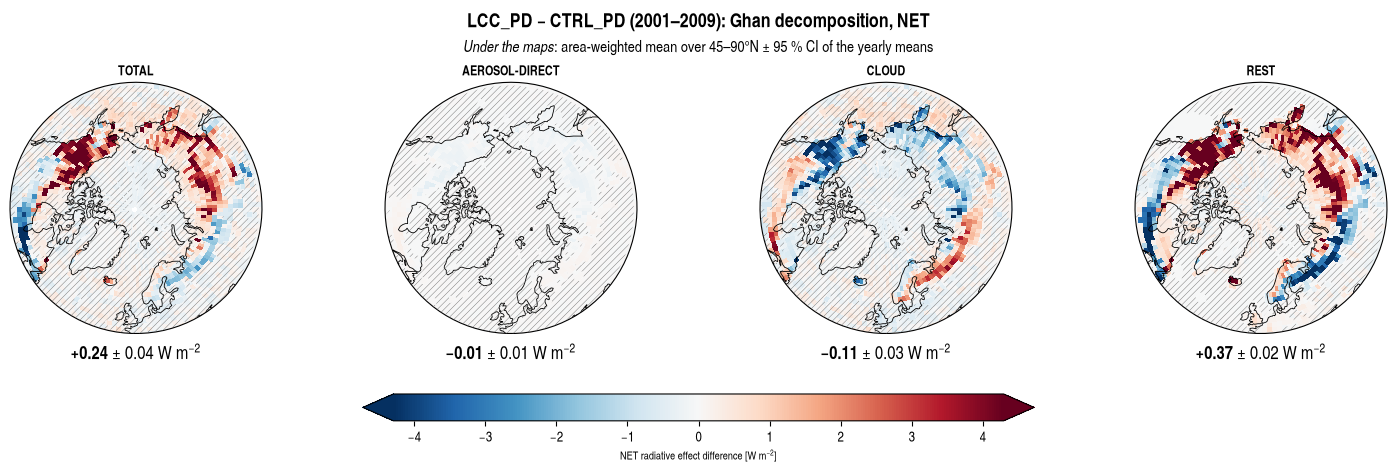

In [9]:
font_figure("H_TeXGyreHerosCn")

## I: Fira Sans

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


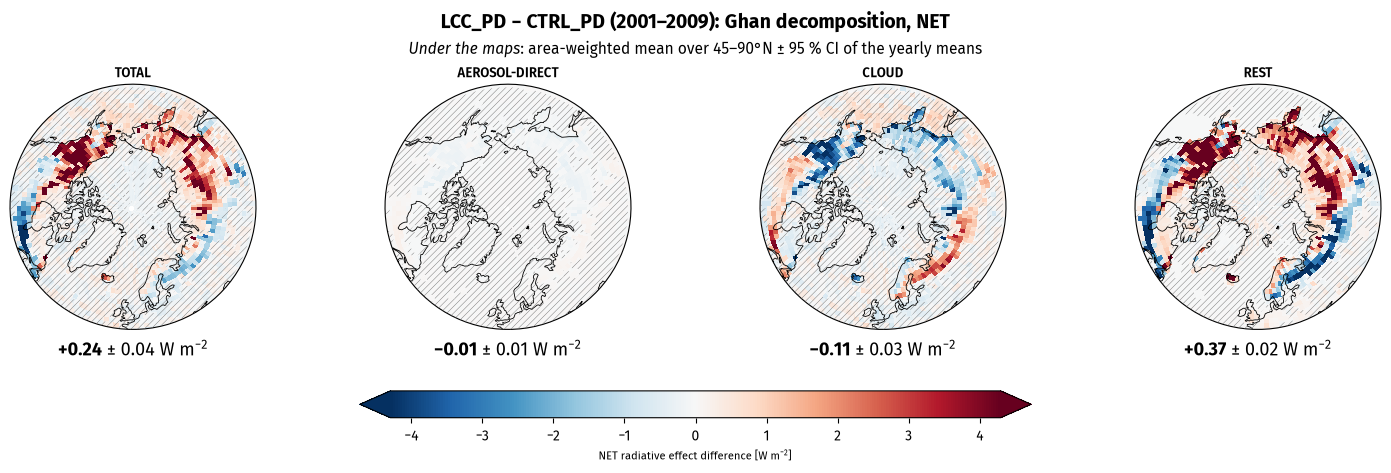

In [10]:
font_figure("I_FiraSans")

## J: Lato

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


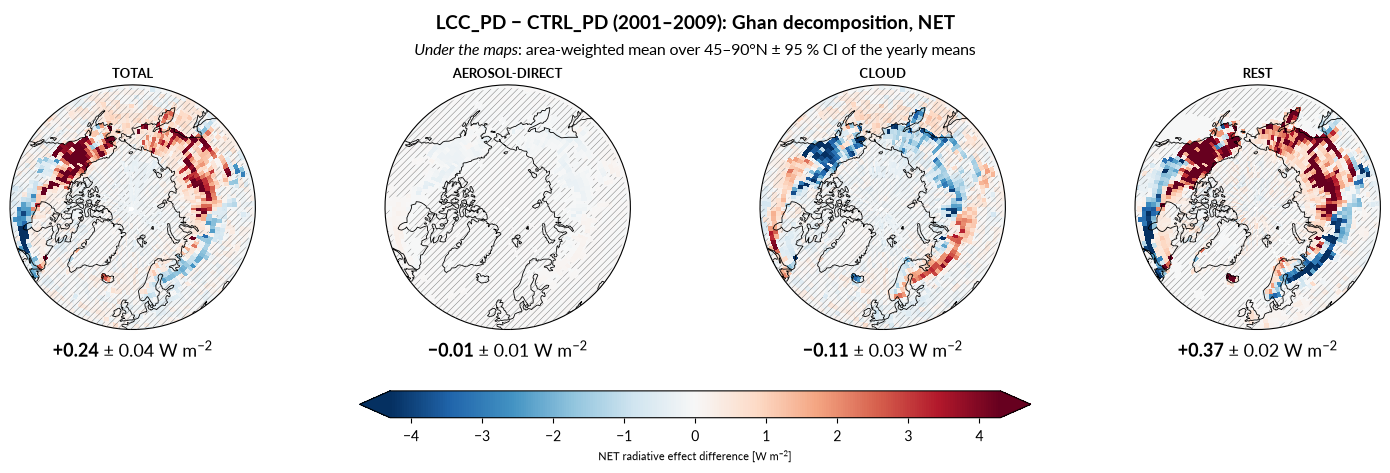

In [11]:
font_figure("J_Lato")

## K: Liberation Serif (Times metrics)

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.0e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


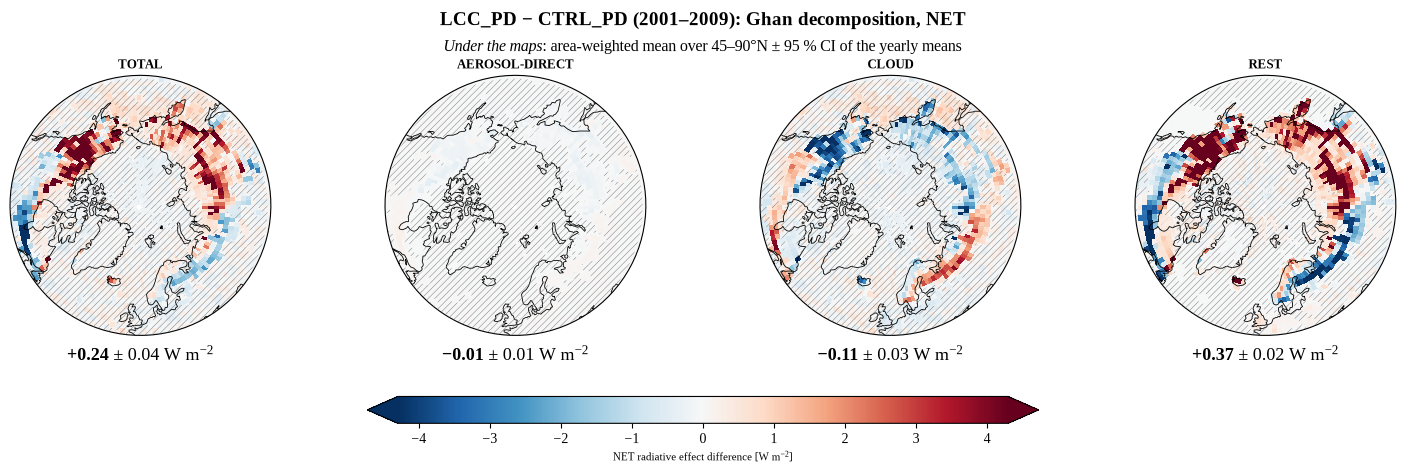

In [12]:
font_figure("K_LiberationSerif")